# 기능 F 굿즈 목업: 굿즈 모양 보존 방식 비교 (10/28)

무지 굿즈 사진에 게임 그림을 인쇄한 목업을 만든다. 굿즈 모양·배경은 그대로 두고 그림만 굿즈 위에 자연스럽게 얹는 것이 목표다. 10/28 조사한 후보(Notion F 페이지 "굿즈 모양 보존 방식 후보")를 모두 같은 입력으로 비교한다. 가설은 F3(합성 + 인페인팅 다듬기)가 가장 낫다는 것이다.

| 후보 | 방식 | 근거 |
|---|---|---|
| F0 | SDXL img2img + IP-Adapter(인쇄할 그림). 10/21 계획(img2img)에 그림을 넣으려고 IP-Adapter를 더함. strength 0.45 / 0.65 | diffusers img2img 문서: strength가 낮을수록 입력과 비슷 |
| F1 | 합성: 인쇄 영역에 그림을 붙이고, 굿즈 사진 밝기로 변위(주름 따라 휘기) + 곱하기 음영. 머그는 원통 곡면으로 가로를 눌러 붙임 | DEV 글 "Realistic Fabric Wrinkles ... Displacement Maps"(밝기 → 변위, 음영 배수 `1 - (1 - shade) × 0.6`) |
| F2 | Qwen-Image-Edit-2509에 굿즈 사진과 그림 두 장 + 지시문 | Qwen-Image-Edit 모델 카드 "keeping certain regions of the image unchanged". 20B라 4bit(bitsandbytes nf4)로 올림 |
| F2' | FLUX.1 Kontext dev로 F1 결과를 지시문으로 다듬기(한 장만 입력받는 모델) | BFL 발표. FLUX.1 Non-Commercial License라 서비스에는 별도 라이선스 필요 |
| F3 | F1 결과의 인쇄 영역만 SDXL 인페인팅(strength 0.3)으로 다듬고, 영역 밖은 F1(=원본) 픽셀로 덮어씀 | diffusers 인페인팅 문서 "black pixels are preserved"(VAE를 거치며 바뀌는지는 문서에 없어 다시 덮어씀) |

- 입력
  - 굿즈: 03 "4-1"에서 받은 무지 굿즈 사진(티셔츠 2, 머그 4, 토트백 3, 후드 2), 긴 변 1024로 줄임
  - 인쇄할 그림: 12 "기능 C" 결과에서 게임마다 첫 요청·seed 0·IP-Adapter 켬 이미지 1장(냥기사 B0, KayKit B2, 0x72 B4)
  - F0·F1·F3: 굿즈 11장 × 그림 3장. F2·F2'은 장당 시간이 길어 종류별 첫 사진 4장 × 그림 3장
- 굿즈 영역: BiRefNet(MIT) 마스크. BiRefNet 모델 코드는 einops·kornia·timm이 필요하다("의존성 설치" 셀). 불러오지 못하면 멈춘다. 10/28 첫 실행에서 이 패키지가 없어 가장자리 색 기준 대체 마스크가 쓰였고, 흰 굿즈·흰 배경 사진에서 배경을 굿즈로 잡아 인쇄 영역이 틀렸다(`ALLOW_MASK_FALLBACK = True`로만 대체 마스크를 씀).
- 인쇄 영역: 마스크 경계 상자 기준 비율(티셔츠·후드 가슴, 토트백 가운데, 머그 몸통)로 자동으로 잡는다. 탐색값이라 "굿즈 마스크·인쇄 영역" 셀 그림으로 확인하고, 틀리면 `PRINT_BOX_OVERRIDE`에 직접 적는다.
- 지표
  - 보존: 인쇄 영역(16px 넓힘, F3 덮어쓰기 경계 포함) 밖에서 원본 대비 SSIM·PSNR (`keep_ssim`, `keep_psnr`), 굿즈 마스크 안·인쇄 영역 밖 SSIM (`prod_ssim`)
  - 그림 반영: 인쇄 영역을 잘라 낸 이미지와 인쇄할 그림의 CLIP 유사도 (`design_sim`). F2는 그림을 다른 자리에 놓을 수 있어 전체 이미지와의 유사도(`design_sim_full`)도 함께 낸다
  - 육안: 굿즈별 비교 그림
- 탐색값(근거 문서 없음): F0 strength 0.45·0.65, IP-Adapter 강도 0.6, F3 strength 0.3, 변위 세기(인쇄 영역 너비의 2%), 인쇄 영역 비율, 머그 원통 반각 60°
- 기록 (`outputs/mockup_f/`)
  - `f_config.json`: 후보별 설정 전문, 입력 목록, 패키지 버전, GPU
  - `masks.csv`, `masks/`, `print_boxes.csv`, `print_boxes.png`
  - `f_records.csv`: 이미지 1장마다 방식·굿즈·그림·설정·생성 시간·최대 VRAM·오류(건너뛴 이유 포함)
  - `f_runs.csv`: 단계마다 시작·종료 시각, 모델 로드 시간, 전체 시간, 장수
  - `f_scored.csv`, `f_summary.csv`, `f_scores.png`, `f_grid_<그림>.png`
- 실행 순서: 위에서부터 차례로. 다시 실행하면 오류 없이 만든 이미지는 건너뛴다.
- 예상 시간(추정): 마스크 1분, F1 1분, F0·F3 약 15분, F2 약 40분 + 첫 다운로드, F2' 약 15분 + 첫 다운로드. F2·F2'은 내려받을 용량이 커서(F2 약 58GB, F2' 약 34GB) "편집 모델 준비 확인" 셀이 디스크 여유·패키지·접근 권한을 먼저 보고 모자라면 건너뛴 이유를 기록한다.
- 10/28 수정: 첫 실행에서 F0를 F3 파이프라인이 올라간 커널에서 `from_pipe` + IP-Adapter로 돌리자 최대 VRAM 24.55GB가 되어 첫 장이 2,095초 걸렸다. F3가 끝나면 파이프라인을 내리고, F0는 07처럼 별도 프로세스에서 img2img 파이프라인을 새로 불러 돌린다.
- GPU를 다른 노트북과 동시에 쓰지 않는다.

## 의존성 설치

In [1]:
# bitsandbytes: F2·F2' 4bit 로드용 (diffusers PipelineQuantizationConfig의 bitsandbytes 백엔드). 설치 후 커널 재시작
# BiRefNet 모델 코드가 einops·kornia·timm을 씀 (없으면 불러오기 실패)
%pip install bitsandbytes einops kornia timm

Note: you may need to restart the kernel to use updated packages.


## 설정

In [2]:
import gc
import importlib.metadata
import json
import os
import platform
import shutil
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageFilter

ROOT = Path('..')
OUT_DIR = ROOT / 'outputs' / 'mockup_f'
OUT_DIR.mkdir(parents=True, exist_ok=True)
REC_CSV = OUT_DIR / 'f_records.csv'
RUNS_CSV = OUT_DIR / 'f_runs.csv'

GOODS_DIR = ROOT / 'data' / 'raw' / 'goods'
SRC_CSV = GOODS_DIR / 'goods_sources.csv'
assert SRC_CSV.exists(), '굿즈 사진이 없음 → 03 "4-1. 무료 사진 사이트에서 무지 굿즈 사진 받기" 셀을 먼저 실행'
GOODS = pd.read_csv(SRC_CSV, keep_default_na=False)
GOODS = GOODS[(GOODS.error == '') & GOODS.file.map(lambda f: (GOODS_DIR / f).exists())].reset_index(drop=True)
assert len(GOODS), '받은 굿즈 사진이 없음'
KIND_EN = {'tshirt': 't-shirt', 'hoodie': 'hoodie', 'tote': 'tote bag', 'mug': 'mug'}
# 원본 사진은 4000px 이상이라 긴 변 1024(8의 배수)로 줄여 모든 방식에 같은 입력으로 씀
MAX_SIDE = 1024


def load_goods(name):
    im = Image.open(GOODS_DIR / name).convert('RGB')
    s = MAX_SIDE / max(im.size)
    w, h = (int(round(im.width * s / 8)) * 8, int(round(im.height * s / 8)) * 8)
    return im.resize((w, h), Image.LANCZOS)


print('굿즈', len(GOODS), '장:', GOODS.groupby('kind').size().to_dict())

# 인쇄할 그림: 12 결과에서 게임마다 첫 요청·seed 0·IP-Adapter 켬
C_DIR = ROOT / 'outputs' / 'promo_c'
DESIGNS = {'nai': C_DIR / 'C_B0_nai_ipa_s0.png', 'kaykit': C_DIR / 'C_B2_kaykit_ipa_s0.png', 'x72': C_DIR / 'C_B4_x72_ipa_s0.png'}
assert all(p.exists() for p in DESIGNS.values()), '12 노트북 결과가 없음'

SDXL_BASE = 'stabilityai/stable-diffusion-xl-base-1.0'
IPA = dict(repo='h94/IP-Adapter', subfolder='sdxl_models', weight_name='ip-adapter_sdxl.bin')
QWEN_EDIT = 'Qwen/Qwen-Image-Edit-2509'
KONTEXT = 'black-forest-labs/FLUX.1-Kontext-dev'
SEED = 0
STEPS, CFG = 30, 7.0
F0_STRENGTHS = [0.45, 0.65]
F0_IPA_SCALE = 0.6
F3_STRENGTH = 0.3
DISP_RATIO = 0.02
SHADE_BLEND = 0.6
MUG_HALF_ANGLE = np.deg2rad(60)
# F2·F2'은 종류별 첫 사진만
EDIT_GOODS = list(GOODS.groupby('kind', sort=False).file.first())


def kind_of(name):
    return GOODS.set_index('file').kind[name]


def prompt_of(kind):
    if kind == 'mug':
        return 'a ceramic mug with a full color illustration printed on its side, product photo, realistic'
    return f'a {KIND_EN[kind]} with a full color illustration printed on the front, product photo, realistic fabric texture'


NEGATIVE = 'text, letters, watermark, logo, lowres, blurry, deformed'
print('그림', list(DESIGNS), '| F2·F2\' 굿즈', EDIT_GOODS)

def pkg_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


def gpu_info():
    try:
        out = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'],
                             capture_output=True, text=True, timeout=30)
        return out.stdout.strip() or out.stderr.strip()
    except Exception as e:
        return f'{type(e).__name__}: {e}'


def append_csv(path, rec):
    pd.DataFrame([rec]).to_csv(path, mode='a', header=not path.exists(), index=False, encoding='utf-8-sig')

굿즈 11 장: {'hoodie': 2, 'mug': 4, 'tote': 3, 'tshirt': 2}
그림 ['nai', 'kaykit', 'x72'] | F2·F2' 굿즈 ['mug_01.jpg', 'tshirt_01.jpg', 'tote_01.jpg', 'hoodie_01.jpg']


## 굿즈 마스크·인쇄 영역

마스크 새로 만들 사진 0 / 11


,file,kind,mask_method,mask_area,sec,width,height
0,mug_01.jpg,mug,birefnet,0.1950,0.76,888,1024
1,mug_02.jpg,mug,birefnet,0.2262,0.35,1024,680
2,mug_03.jpg,mug,birefnet,0.0985,0.34,1024,680
3,mug_04.jpg,mug,birefnet,0.1858,0.34,1024,680
4,tshirt_01.jpg,tshirt,birefnet,0.2570,0.34,1024,680
5,tshirt_02.jpg,tshirt,birefnet,0.2505,0.34,1024,680
6,tote_01.jpg,tote,birefnet,0.2416,0.34,1024,680
7,tote_02.jpg,tote,birefnet,0.2408,0.33,680,1024
8,tote_03.jpg,tote,birefnet,0.1282,0.33,576,1024
9,hoodie_01.jpg,hoodie,birefnet,0.3183,0.33,1024,768


,file,kind,x,y,w,h,source
0,mug_01.jpg,mug,388,555,210,143,auto
1,mug_02.jpg,mug,435,276,187,128,auto
2,mug_03.jpg,mug,189,411,154,105,auto
3,mug_04.jpg,mug,380,308,190,130,auto
4,tshirt_01.jpg,tshirt,400,227,216,148,auto
5,tshirt_02.jpg,tshirt,413,184,198,136,auto
6,tote_01.jpg,tote,410,284,213,146,auto
7,tote_02.jpg,tote,220,475,217,148,auto
8,tote_03.jpg,tote,253,550,143,97,auto
9,hoodie_01.jpg,hoodie,489,222,220,150,auto


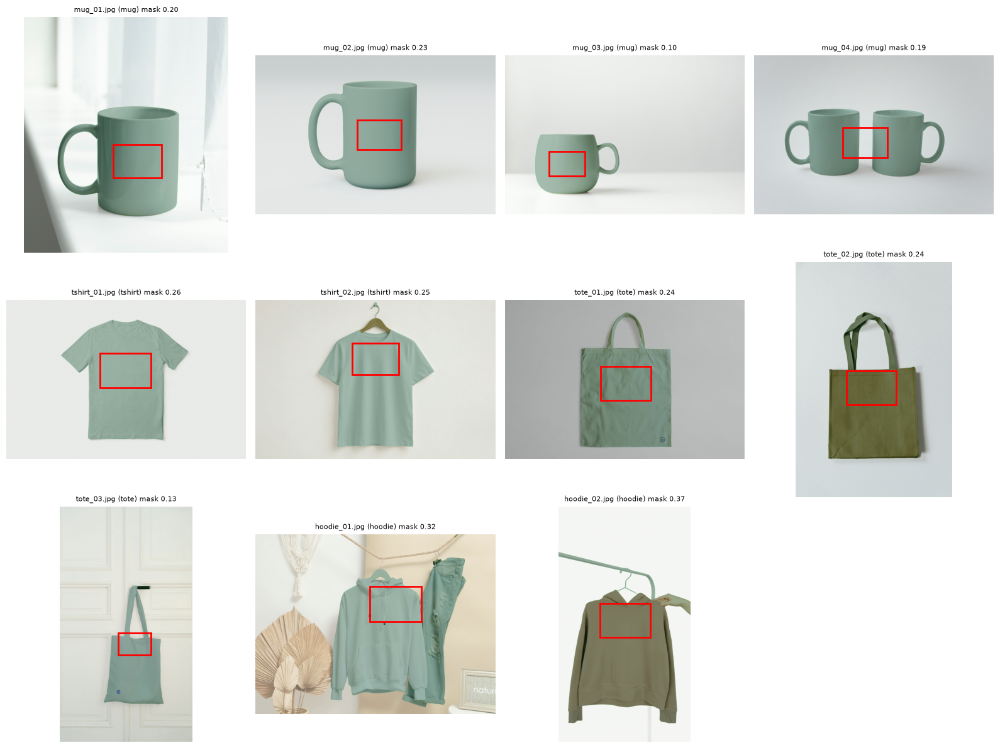

In [3]:
MASK_DIR = OUT_DIR / 'masks'
MASK_DIR.mkdir(exist_ok=True)
BIREFNET = 'ZhengPeng7/BiRefNet'
# 가장자리 색 기준 대체 마스크는 흰 굿즈·흰 배경 사진에서 틀림(10/28 확인) → 기본은 쓰지 않고 멈춤
ALLOW_MASK_FALLBACK = False


def mask_fallback(img):
    # BiRefNet을 못 쓸 때: 사진 가장자리 색(무지 배경)과 다른 픽셀을 굿즈로 봄
    a = np.asarray(img).astype(np.float32)
    border = np.concatenate([a[:8].reshape(-1, 3), a[-8:].reshape(-1, 3), a[:, :8].reshape(-1, 3), a[:, -8:].reshape(-1, 3)])
    d = np.linalg.norm(a - np.median(border, 0), axis=2)
    return (d > 30).astype(np.float32)


def make_masks():
    import torch
    # 이미 만든 마스크(파일과 masks.csv 기록이 모두 있는 사진)는 건너뜀
    old = pd.read_csv(OUT_DIR / 'masks.csv', keep_default_na=False) if (OUT_DIR / 'masks.csv').exists() else pd.DataFrame(columns=['file'])
    todo = [g for g in GOODS.itertuples() if g.file not in set(old.file) or not (MASK_DIR / f'{Path(g.file).stem}.png').exists()]
    print('마스크 새로 만들 사진', len(todo), '/', len(GOODS))
    if not todo:
        return old[old.file.isin(GOODS.file)].reset_index(drop=True)
    rows, model, method = [], None, 'birefnet'
    try:
        from torchvision import transforms
        from transformers import AutoModelForImageSegmentation
        model = AutoModelForImageSegmentation.from_pretrained(BIREFNET, trust_remote_code=True).to('cuda').eval().float()
        tf = transforms.Compose([transforms.Resize((1024, 1024)), transforms.ToTensor(),
                                 transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
    except Exception as e:
        if not ALLOW_MASK_FALLBACK:
            raise RuntimeError('BiRefNet을 불러오지 못함 → "의존성 설치" 셀(einops, kornia, timm) 실행 후 커널 재시작: '
                               f'{type(e).__name__}: {str(e)[:200]}') from e
        method = f'fallback ({type(e).__name__}: {str(e)[:120]})'
        print('BiRefNet 불러오기 실패 → 가장자리 색 기준 마스크로 대체:', method)
    for g in todo:
        img = load_goods(g.file)
        t0 = time.perf_counter()
        if model is not None:
            with torch.no_grad():
                pred = model(tf(img).unsqueeze(0).to('cuda'))[-1].sigmoid()[0, 0].float().cpu().numpy()
            m = np.asarray(Image.fromarray((pred * 255).astype(np.uint8)).resize(img.size, Image.BILINEAR)) / 255.0
        else:
            m = mask_fallback(img)
        Image.fromarray((m * 255).astype(np.uint8)).save(MASK_DIR / f'{Path(g.file).stem}.png')
        rows.append(dict(file=g.file, kind=g.kind, mask_method=method, mask_area=round(float((m > 0.5).mean()), 4),
                         sec=round(time.perf_counter() - t0, 2), width=img.width, height=img.height))
    if model is not None:
        del model
        gc.collect()
        torch.cuda.empty_cache()
    new = pd.DataFrame(rows)
    return pd.concat([old[old.file.isin(GOODS.file) & ~old.file.isin(new.file)], new], ignore_index=True)


def load_mask(name):
    return np.asarray(Image.open(MASK_DIR / f'{Path(name).stem}.png')).astype(np.float32) / 255.0


masks = make_masks()
masks.to_csv(OUT_DIR / 'masks.csv', index=False, encoding='utf-8-sig')
display(masks)

# 인쇄 영역 비율 (경계 상자 기준, 탐색값): (가로 중심 기준, 너비 비율, 위쪽 위치 비율, 최대 높이 비율)
BOX_RULE = {'tshirt': (0.40, 0.28, 0.40), 'hoodie': (0.38, 0.30, 0.38), 'tote': (0.55, 0.40, 0.45), 'mug': (0.60, None, 0.45)}
# 자동 영역이 틀린 사진은 여기 (x, y, w, h)를 적음 (예: {'mug_02.jpg': (300, 260, 360, 240)})
PRINT_BOX_OVERRIDE = {}


def print_box(name, kind, aspect):
    if name in PRINT_BOX_OVERRIDE:
        return tuple(PRINT_BOX_OVERRIDE[name]) + ('override',)
    m = load_mask(name) > 0.5
    ys, xs = np.nonzero(m)
    x0, x1, y0, y1 = xs.min(), xs.max(), ys.min(), ys.max()
    bw, bh = x1 - x0 + 1, y1 - y0 + 1
    wr, top, hmax = BOX_RULE[kind]
    if kind == 'mug':
        # 손잡이를 빼려고 세로로 많이 채워진 열(몸통)만 씀
        col = m[y0:y1 + 1, x0:x1 + 1].sum(0)
        body = np.nonzero(col >= 0.6 * col.max())[0] + x0
        cx, w = body.mean(), wr * len(body)
    else:
        cx, w = np.median(xs), wr * bw
    h = w / aspect
    if h > hmax * bh:
        h = hmax * bh
        w = h * aspect
    y = y0 + (top * bh if top is not None else (bh - h) / 2)
    return int(cx - w / 2), int(y), int(w), int(h), 'auto'


DESIGN_ASPECT = {g: Image.open(p).width / Image.open(p).height for g, p in DESIGNS.items()}
assert len(set(round(a, 3) for a in DESIGN_ASPECT.values())) == 1
ASPECT = list(DESIGN_ASPECT.values())[0]
boxes = pd.DataFrame([dict(file=g.file, kind=g.kind, **dict(zip(['x', 'y', 'w', 'h', 'source'], print_box(g.file, g.kind, ASPECT))))
                      for g in GOODS.itertuples()])
boxes.to_csv(OUT_DIR / 'print_boxes.csv', index=False, encoding='utf-8-sig')
BOX = {r.file: (r.x, r.y, r.w, r.h) for r in boxes.itertuples()}
display(boxes)

n = len(GOODS)
fig, axes = plt.subplots(int(np.ceil(n / 4)), 4, figsize=(16, 4 * int(np.ceil(n / 4))), squeeze=False)
for ax in axes.flat:
    ax.axis('off')
for ax, g in zip(axes.flat, GOODS.itertuples()):
    ax.imshow(load_goods(g.file))
    ax.imshow(load_mask(g.file), alpha=0.35, cmap='Greens')
    x, y, w, h = BOX[g.file]
    ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, color='red', lw=2))
    ax.set_title(f'{g.file} ({g.kind}) mask {masks.set_index("file").mask_area[g.file]:.2f}', fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / 'print_boxes.png', dpi=60)
plt.show()

## F1 합성 (GPU 안 씀)

In [4]:
def bilinear(img, yy, xx):
    h, w = img.shape[:2]
    yy, xx = np.clip(yy, 0, h - 1), np.clip(xx, 0, w - 1)
    y0, x0 = np.floor(yy).astype(int), np.floor(xx).astype(int)
    y1, x1 = np.minimum(y0 + 1, h - 1), np.minimum(x0 + 1, w - 1)
    wy, wx = (yy - y0)[..., None], (xx - x0)[..., None]
    return (img[y0, x0] * (1 - wy) * (1 - wx) + img[y0, x1] * (1 - wy) * wx + img[y1, x0] * wy * (1 - wx) + img[y1, x1] * wy * wx)


def print_region(name):
    # 인쇄 영역 ∩ 굿즈 마스크 (전체 크기)
    x, y, w, h = BOX[name]
    m = load_mask(name)
    r = np.zeros_like(m)
    r[y:y + h, x:x + w] = m[y:y + h, x:x + w]
    return r


def compose_f1(name, design_path):
    img = load_goods(name)
    kind = kind_of(name)
    x, y, w, h = BOX[name]
    d = np.asarray(Image.open(design_path).convert('RGB').resize((w, h), Image.LANCZOS), dtype=np.float64)
    yy, xx = np.mgrid[0:h, 0:w].astype(np.float64)
    if kind == 'mug':
        # 원통 곡면: 화면 가로 위치 u → 그림 가로 위치 θ/θmax (가장자리일수록 눌림)
        u = (xx + 0.5) / w * 2 - 1
        xx = (np.arcsin(np.clip(u, -1, 1) * np.sin(MUG_HALF_ANGLE)) / MUG_HALF_ANGLE + 1) / 2 * w - 0.5
    gray = np.asarray(img.convert('L').filter(ImageFilter.GaussianBlur(2)), dtype=np.float64)[y:y + h, x:x + w]
    region = load_mask(name)[y:y + h, x:x + w]
    inside = gray[region > 0.5] if (region > 0.5).any() else gray.ravel()
    lo, hi = np.percentile(inside, 2), np.percentile(inside, 98)
    ln = np.clip((gray - lo) / max(hi - lo, 1e-6), 0, 1)
    disp = (ln - 0.5) * DISP_RATIO * w
    warped = bilinear(d, yy + disp, xx + disp)
    shade = np.clip(gray / max(np.percentile(inside, 95), 1e-6), 0, 1)
    warped = warped * (1 - (1 - shade) * SHADE_BLEND)[..., None]
    a = np.asarray(img, dtype=np.float64).copy()
    alpha = region[..., None]
    a[y:y + h, x:x + w] = a[y:y + h, x:x + w] * (1 - alpha) + warped * alpha
    return Image.fromarray(a.clip(0, 255).astype(np.uint8))


def out_name(method, name, game):
    return f'{method}__{Path(name).stem}__{game}.png'


recs = {x['file']: x for x in pd.read_csv(REC_CSV, keep_default_na=False).to_dict('records')} if REC_CSV.exists() else {}


def done(f):
    return recs.get(f, {}).get('error', 'x') == '' and (OUT_DIR / f).exists()


def save_rec(rec):
    recs[rec['file']] = rec
    pd.DataFrame(list(recs.values())).to_csv(REC_CSV, index=False, encoding='utf-8-sig')


started, t_all, n_new = time.strftime('%Y-%m-%d %H:%M:%S'), time.perf_counter(), 0
for g in GOODS.itertuples():
    for game, dp in DESIGNS.items():
        f = out_name('F1', g.file, game)
        if done(f):
            continue
        rec = dict(file=f, method='F1', goods=g.file, kind=g.kind, design=game, params=json.dumps(
            dict(disp_ratio=DISP_RATIO, shade_blend=SHADE_BLEND, mug_half_angle_deg=60 if g.kind == 'mug' else None)), error='')
        try:
            t0 = time.perf_counter()
            compose_f1(g.file, dp).save(OUT_DIR / f)
            rec['sec'] = round(time.perf_counter() - t0, 2)
            n_new += 1
        except Exception as e:
            rec['error'] = f'{type(e).__name__}: {e}'[:300]
        save_rec(rec)
append_csv(RUNS_CSV, dict(stage='F1', started=started, ended=time.strftime('%Y-%m-%d %H:%M:%S'),
                          sec_total=round(time.perf_counter() - t_all, 1), n_new=n_new, load_sec=0, peak_vram_gb=0))
print('F1 새로 만든 장수', n_new)

F1 새로 만든 장수 0


## F3 인페인팅 다듬기·F0 img2img (SDXL)

In [5]:
import torch
from diffusers import StableDiffusionXLImg2ImgPipeline, StableDiffusionXLInpaintPipeline


def dilate(m, px):
    return np.asarray(Image.fromarray((m * 255).astype(np.uint8)).filter(ImageFilter.MaxFilter(2 * px + 1))) / 255.0


def feather(m, px):
    return np.asarray(Image.fromarray((m * 255).astype(np.uint8)).filter(ImageFilter.GaussianBlur(px))) / 255.0


todo3 = [(g, game) for g in GOODS.itertuples() for game in DESIGNS if not done(out_name('F3', g.file, game))
         and done(out_name('F1', g.file, game))]
todo0 = [(g, game, s) for g in GOODS.itertuples() for game in DESIGNS for s in F0_STRENGTHS
         if not done(out_name(f'F0s{s}', g.file, game))]
print('F3', len(todo3), '장 | F0', len(todo0), '장')
if todo3:
    started, t_all = time.strftime('%Y-%m-%d %H:%M:%S'), time.perf_counter()
    pipe = StableDiffusionXLInpaintPipeline.from_pretrained(SDXL_BASE, torch_dtype=torch.bfloat16).to('cuda')
    load_sec = round(time.perf_counter() - t_all, 1)
    peak = 0.0
    # F3: F1 결과의 인쇄 영역만 다시 그리고, 영역 밖은 F1 픽셀로 덮어씀
    for g, game in todo3:
        f = out_name('F3', g.file, game)
        comp = Image.open(OUT_DIR / out_name('F1', g.file, game)).convert('RGB')
        m = dilate(print_region(g.file), 8)
        rec = dict(file=f, method='F3', goods=g.file, kind=g.kind, design=game, params=json.dumps(
            dict(base='F1', strength=F3_STRENGTH, steps=STEPS, cfg=CFG, prompt=prompt_of(g.kind), negative=NEGATIVE,
                 mask='print region dilated 8px, paste back with 4px feather')), error='')
        try:
            torch.cuda.reset_peak_memory_stats()
            t0 = time.perf_counter()
            out = pipe(prompt=prompt_of(g.kind), negative_prompt=NEGATIVE, image=comp,
                       mask_image=Image.fromarray((m * 255).astype(np.uint8)), strength=F3_STRENGTH,
                       num_inference_steps=STEPS, guidance_scale=CFG, width=comp.width, height=comp.height,
                       generator=torch.Generator('cpu').manual_seed(SEED)).images[0].resize(comp.size)
            a = feather(m, 4)[..., None]
            res = np.asarray(out, dtype=np.float64) * a + np.asarray(comp, dtype=np.float64) * (1 - a)
            Image.fromarray(res.clip(0, 255).astype(np.uint8)).save(OUT_DIR / f)
            rec['sec'] = round(time.perf_counter() - t0, 2)
            rec['peak_vram_gb'] = round(torch.cuda.max_memory_allocated() / 1024**3, 2)
            peak = max(peak, rec['peak_vram_gb'])
        except Exception as e:
            rec['error'] = f'{type(e).__name__}: {e}'[:300]
        save_rec(rec)
        print(f, rec.get('sec'), rec['error'][:100], flush=True)
    append_csv(RUNS_CSV, dict(stage='F3 (SDXL inpaint)', started=started, ended=time.strftime('%Y-%m-%d %H:%M:%S'),
                              sec_total=round(time.perf_counter() - t_all, 1), n_new=len(todo3), load_sec=load_sec, peak_vram_gb=peak))
    del pipe
    gc.collect()
    torch.cuda.empty_cache()

# F0: 07처럼 새 프로세스에서 img2img 파이프라인을 bf16으로 새로 불러와 IP-Adapter를 붙임
# (10/28 첫 실행: F3 파이프라인을 둔 채 from_pipe + IP-Adapter → 이 커널 최대 VRAM 24.55GB, 첫 장 2,095초)
CHILD_F0 = r"""
import csv, json, os, sys, time
import torch
from PIL import Image
from diffusers import StableDiffusionXLImg2ImgPipeline

a = json.loads(sys.stdin.read())
FIELDS = ['file', 'method', 'goods', 'kind', 'design', 'params', 'sec', 'peak_vram_gb', 'load_sec', 'error']
t0 = time.perf_counter()
pipe = StableDiffusionXLImg2ImgPipeline.from_pretrained(a['model'], torch_dtype=torch.bfloat16)
pipe.load_ip_adapter(a['ipa_repo'], subfolder=a['ipa_subfolder'], weight_name=a['ipa_weight'])
pipe.to('cuda')
pipe.set_ip_adapter_scale(a['ipa_scale'])
pipe.set_progress_bar_config(disable=True)
load_sec = round(time.perf_counter() - t0, 1)
print('LOADED', load_sec, 's', flush=True)
for t in a['tasks']:
    rec = {k: t.get(k, '') for k in FIELDS}
    rec['load_sec'] = load_sec
    try:
        torch.cuda.reset_peak_memory_stats()
        t1 = time.perf_counter()
        img = Image.open(t['goods_path']).convert('RGB')
        out = pipe(prompt=t['prompt'], negative_prompt=a['negative'], image=img, strength=t['strength'],
                   ip_adapter_image=Image.open(t['design_path']).convert('RGB'), num_inference_steps=a['steps'],
                   guidance_scale=a['cfg'], generator=torch.Generator('cpu').manual_seed(a['seed'])).images[0]
        out.resize(img.size).save(t['out'])
        rec['sec'] = round(time.perf_counter() - t1, 2)
        rec['peak_vram_gb'] = round(torch.cuda.max_memory_allocated() / 1024**3, 2)
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'[:300]
    new = not os.path.exists(a['csv'])
    with open(a['csv'], 'a', newline='', encoding='utf-8') as fh:
        w = csv.DictWriter(fh, fieldnames=FIELDS)
        if new:
            w.writeheader()
        w.writerow(rec)
    print(t['file'], rec.get('sec'), 's', rec.get('peak_vram_gb'), 'GB', rec['error'][:100], flush=True)
"""
if todo0:
    started, t_all = time.strftime('%Y-%m-%d %H:%M:%S'), time.perf_counter()
    tasks = []
    for g, game, s in todo0:
        gpath = OUT_DIR / f'_goods_{Path(g.file).stem}.png'
        if not gpath.exists():
            load_goods(g.file).save(gpath)
        f = out_name(f'F0s{s}', g.file, game)
        tasks.append(dict(file=f, method=f'F0s{s}', goods=g.file, kind=g.kind, design=game, strength=s, prompt=prompt_of(g.kind),
                          goods_path=str(gpath.resolve()), design_path=str(DESIGNS[game].resolve()), out=str((OUT_DIR / f).resolve()),
                          params=json.dumps(dict(strength=s, ipa_scale=F0_IPA_SCALE, steps=STEPS, cfg=CFG, prompt=prompt_of(g.kind),
                                                 negative=NEGATIVE, process='separate (fresh img2img pipeline)'))))
    F0_TMP = OUT_DIR / 'f0_child.csv'
    F0_TMP.unlink(missing_ok=True)
    proc = subprocess.Popen([sys.executable, '-c', CHILD_F0], stdin=subprocess.PIPE, stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT, text=True, encoding='utf-8', errors='replace',
                            env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
    proc.stdin.write(json.dumps(dict(model=SDXL_BASE, ipa_repo=IPA['repo'], ipa_subfolder=IPA['subfolder'], ipa_weight=IPA['weight_name'],
                                     ipa_scale=F0_IPA_SCALE, negative=NEGATIVE, steps=STEPS, cfg=CFG, seed=SEED,
                                     csv=str(F0_TMP.resolve()), tasks=tasks)))
    proc.stdin.close()
    # 진행 상황을 셀 출력에 바로 보여 줌
    for line in proc.stdout:
        print(line, end='', flush=True)
    rc = proc.wait()
    got = pd.read_csv(F0_TMP, keep_default_na=False).to_dict('records') if F0_TMP.exists() else []
    for x in got:
        save_rec(x)
    got_files = {x['file'] for x in got}
    for t in tasks:
        if t['file'] not in got_files:
            save_rec({k: t[k] for k in ['file', 'method', 'goods', 'kind', 'design', 'params']} | dict(error=f'프로세스 종료 코드 {rc}'))
    peaks = [float(x['peak_vram_gb']) for x in got if x['peak_vram_gb'] != '']
    append_csv(RUNS_CSV, dict(stage='F0 (SDXL img2img + IP-Adapter, 별도 프로세스)', started=started,
                              ended=time.strftime('%Y-%m-%d %H:%M:%S'), sec_total=round(time.perf_counter() - t_all, 1),
                              n_new=sum(x['error'] == '' for x in got), load_sec=got[0]['load_sec'] if got else None,
                              peak_vram_gb=max(peaks) if peaks else None))
    print('F0 종료 코드', rc, '| 새로 만든 장수', sum(x['error'] == '' for x in got))


c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Multiple distributions found for package optimum. Picked distribution: optimum
W1028 14:58:37.405000 3568 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1028 14:58:37.502000 3568 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Unable to import `torchao` Tensor objects. This may affect loading ch

F3 0 장 | F0 65 장
Multiple distributions found for package optimum. Picked distribution: optimum
W1028 14:59:08.011000 58736 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1028 14:59:08.108000 58736 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.


## 편집 모델 준비 확인 (F2·F2')

In [6]:
import importlib.util

import diffusers
from huggingface_hub import HfApi, constants, snapshot_download

# 편집 모델 준비 확인: 패키지, 접근 권한, 내려받을 용량 대비 디스크 여유. 모자라면 건너뛴 이유를 기록함
EDIT_MODELS = {
    'F2': dict(repo=QWEN_EDIT, pipeline='QwenImageEditPlusPipeline', quantize=['transformer', 'text_encoder']),
    "F2'": dict(repo=KONTEXT, pipeline='FluxKontextPipeline', quantize=['transformer', 'text_encoder_2']),
}
DISK_MARGIN_GB = 10
api = HfApi()
cache_dir = Path(constants.HF_HUB_CACHE)
cache_dir.mkdir(parents=True, exist_ok=True)
edit_ready = {}
for m, c in EDIT_MODELS.items():
    reason = ''
    if not hasattr(diffusers, c['pipeline']):
        reason = f"설치된 diffusers {diffusers.__version__}에 {c['pipeline']} 없음"
    elif importlib.util.find_spec('bitsandbytes') is None:
        reason = 'bitsandbytes 없음 (4bit로 올리는 데 필요) → %pip install bitsandbytes'
    else:
        try:
            snapshot_download(c['repo'], local_files_only=True, allow_patterns=['*.json', '*.safetensors', '*.txt', '*.model'])
            c['need_gb'] = 0.0
        except Exception:
            try:
                info = api.model_info(c['repo'], files_metadata=True)
                c['need_gb'] = round(sum((s.size or 0) for s in info.siblings
                                         if s.rfilename.endswith(('.json', '.safetensors', '.txt', '.model'))) / 1024**3, 1)
            except Exception as e:
                reason = f'모델 정보를 읽을 수 없음 (gated면 Hugging Face 로그인·라이선스 동의 필요): {type(e).__name__}'
        if not reason:
            free = shutil.disk_usage(cache_dir).free / 1024**3
            c['free_gb'] = round(free, 1)
            if c['need_gb'] and free - c['need_gb'] < DISK_MARGIN_GB:
                reason = f"디스크 부족: 받을 용량 {c['need_gb']}GB, 여유 {free:.1f}GB (남길 여유 {DISK_MARGIN_GB}GB)"
    c['skip_reason'] = reason
    edit_ready[m] = not reason
    print(m, c['repo'], '| 준비됨' if not reason else '| 건너뜀: ' + reason, '| 받을 용량', c.get('need_gb'), 'GB | 캐시', cache_dir)

F2 Qwen/Qwen-Image-Edit-2509 | 준비됨 | 받을 용량 53.8 GB | 캐시 C:\Users\Administrator\.cache\huggingface\hub
F2' black-forest-labs/FLUX.1-Kontext-dev | 준비됨 | 받을 용량 53.9 GB | 캐시 C:\Users\Administrator\.cache\huggingface\hub


## F2·F2' 생성 (별도 프로세스)

In [7]:
CHILD_EDIT = r"""
import csv, json, os, sys, time
import numpy as np
import torch
import diffusers
from diffusers.quantizers import PipelineQuantizationConfig
from PIL import Image

a = json.loads(sys.stdin.read())
FIELDS = ['file', 'method', 'goods', 'kind', 'design', 'params', 'sec', 'peak_vram_gb', 'load_sec', 'error']
t0 = time.perf_counter()
q = PipelineQuantizationConfig(quant_backend='bitsandbytes_4bit',
                               quant_kwargs=dict(load_in_4bit=True, bnb_4bit_quant_type='nf4', bnb_4bit_compute_dtype=torch.bfloat16),
                               components_to_quantize=a['quantize'])
pipe = getattr(diffusers, a['pipeline']).from_pretrained(a['repo'], quantization_config=q, torch_dtype=torch.bfloat16)
pipe.enable_model_cpu_offload()
load_sec = round(time.perf_counter() - t0, 1)
print('LOADED', load_sec, flush=True)
for t in a['tasks']:
    rec = {k: t.get(k, '') for k in FIELDS}
    rec['load_sec'] = load_sec
    try:
        torch.cuda.reset_peak_memory_stats()
        t1 = time.perf_counter()
        imgs = [Image.open(p).convert('RGB') for p in t['inputs']]
        kw = dict(image=imgs if len(imgs) > 1 else imgs[0], prompt=t['prompt'], num_inference_steps=a['steps'],
                  generator=torch.Generator('cpu').manual_seed(a['seed']))
        kw.update(a['extra'])
        out = pipe(**kw).images[0]
        out.save(t['out'])
        rec['sec'] = round(time.perf_counter() - t1, 2)
        rec['peak_vram_gb'] = round(torch.cuda.max_memory_allocated() / 1024**3, 2)
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'[:300]
    new = not os.path.exists(a['csv'])
    with open(a['csv'], 'a', newline='', encoding='utf-8') as fh:
        w = csv.DictWriter(fh, fieldnames=FIELDS)
        if new:
            w.writeheader()
        w.writerow(rec)
    print(t['file'], rec.get('sec'), rec['error'][:100], flush=True)
"""

EDIT_PROMPT = {
    'F2': lambda k: (f"Print the illustration from the second image on the {'side' if k == 'mug' else 'front'} of the {KIND_EN[k]} "
                     f"in the first image, as a printed graphic that follows its {'curved surface' if k == 'mug' else 'fabric folds'} "
                     f"and lighting. Keep the {KIND_EN[k]}, its shape, its color and the background unchanged."),
    "F2'": lambda k: (f"Make the printed illustration look naturally printed on the {KIND_EN[k]}, following its "
                      f"{'curved surface' if k == 'mug' else 'fabric folds'} and lighting. Keep the illustration, the "
                      f"{KIND_EN[k]}, its shape and the background unchanged."),
}
EDIT_ARGS = {'F2': dict(steps=40, extra=dict(true_cfg_scale=4.0, negative_prompt=' ', guidance_scale=1.0)),
             "F2'": dict(steps=28, extra=dict(guidance_scale=2.5))}
EDIT_TMP = OUT_DIR / 'edit_child.csv'
for m, c in EDIT_MODELS.items():
    tasks = []
    for name in EDIT_GOODS:
        k = kind_of(name)
        for game in DESIGNS:
            f = out_name(m.replace("'", 'p'), name, game)
            if done(f):
                continue
            base = dict(file=f, method=m, goods=name, kind=k, design=game)
            if not edit_ready[m]:
                save_rec(dict(base, params='', error='건너뜀: ' + c['skip_reason']))
                continue
            gpath = OUT_DIR / f'_goods_{Path(name).stem}.png'
            load_goods(name).save(gpath)
            inputs = [str(gpath.resolve()), str(DESIGNS[game].resolve())] if m == 'F2' else [str((OUT_DIR / out_name('F1', name, game)).resolve())]
            tasks.append(dict(base, inputs=inputs, out=str((OUT_DIR / f).resolve()), prompt=EDIT_PROMPT[m](k),
                              params=json.dumps(dict(repo=c['repo'], prompt=EDIT_PROMPT[m](k), inputs=['goods', 'design'] if m == 'F2' else ['F1'],
                                                     quant='bitsandbytes nf4', seed=SEED, **EDIT_ARGS[m]))))
    if not tasks:
        print(m, '할 일 없음 (완료 또는 건너뜀)')
        continue
    started, t_all = time.strftime('%Y-%m-%d %H:%M:%S'), time.perf_counter()
    EDIT_TMP.unlink(missing_ok=True)
    p = subprocess.run([sys.executable, '-c', CHILD_EDIT], input=json.dumps(dict(
        repo=c['repo'], pipeline=c['pipeline'], quantize=c['quantize'], seed=SEED, csv=str(EDIT_TMP.resolve()), tasks=tasks,
        **EDIT_ARGS[m])), capture_output=True, text=True, encoding='utf-8', errors='replace', env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
    print(p.stdout[-1500:])
    if p.returncode != 0:
        print(m, '프로세스 종료 코드', p.returncode)
        print(p.stderr[-3000:])
    got = pd.read_csv(EDIT_TMP, keep_default_na=False).to_dict('records') if EDIT_TMP.exists() else []
    got_files = {x['file'] for x in got}
    for x in got:
        save_rec(x)
    for t in tasks:
        if t['file'] not in got_files:
            save_rec({k: t[k] for k in ['file', 'method', 'goods', 'kind', 'design', 'params']} | dict(
                error=f'프로세스 종료 코드 {p.returncode}: {p.stderr[-200:]}'))
    append_csv(RUNS_CSV, dict(stage=m, started=started, ended=time.strftime('%Y-%m-%d %H:%M:%S'),
                              sec_total=round(time.perf_counter() - t_all, 1), n_new=sum(x['error'] == '' for x in got),
                              load_sec=got[0]['load_sec'] if got else None,
                              peak_vram_gb=max([float(x['peak_vram_gb']) for x in got if x['peak_vram_gb'] != ''], default=None)))

config = dict(
    saved_at=time.strftime('%Y-%m-%d %H:%M:%S'), goods=GOODS[['file', 'kind', 'site', 'page']].to_dict('records'),
    designs={g: str(p) for g, p in DESIGNS.items()}, max_side=MAX_SIDE, print_box_rule=BOX_RULE, print_box_override=PRINT_BOX_OVERRIDE,
    mask_model=BIREFNET, seed=SEED,
    F0=dict(model=SDXL_BASE, ip_adapter=IPA, strengths=F0_STRENGTHS, ipa_scale=F0_IPA_SCALE, steps=STEPS, cfg=CFG),
    F1=dict(disp_ratio=DISP_RATIO, shade_blend=SHADE_BLEND, mug_half_angle_deg=60),
    F2=dict(EDIT_MODELS['F2'], args=EDIT_ARGS['F2'], prompt_example=EDIT_PROMPT['F2']('tshirt'), goods=EDIT_GOODS),
    F2p=dict(EDIT_MODELS["F2'"], args=EDIT_ARGS["F2'"], prompt_example=EDIT_PROMPT["F2'"]('tshirt'), goods=EDIT_GOODS),
    F3=dict(model=SDXL_BASE, strength=F3_STRENGTH, steps=STEPS, cfg=CFG, mask_dilate_px=8, feather_px=4),
    prompt_example=prompt_of('tshirt'), negative=NEGATIVE,
    versions={p: pkg_version(p) for p in ['torch', 'diffusers', 'transformers', 'accelerate', 'bitsandbytes', 'pillow', 'numpy']},
    python=platform.python_version(), gpu=gpu_info())
(OUT_DIR / 'f_config.json').write_text(json.dumps(config, ensure_ascii=False, indent=1, default=str), encoding='utf-8')
fr = pd.read_csv(REC_CSV, keep_default_na=False)
print('기록', len(fr), '장 | 오류·건너뜀', (fr.error != '').sum())
display(fr.groupby('method').agg(n=('file', 'size'), ok=('error', lambda s: (s == '').sum())))

LOADED 535.4
F2__mug_01__nai.png 687.56 
F2__mug_01__kaykit.png 694.08 
F2__mug_01__x72.png 602.59 
F2__tshirt_01__nai.png 546.29 
F2__tshirt_01__kaykit.png 546.24 
F2__tshirt_01__x72.png 546.4 
F2__tote_01__nai.png 555.97 
F2__tote_01__kaykit.png 597.69 
F2__tote_01__x72.png 582.55 
F2__hoodie_01__nai.png 599.61 
F2__hoodie_01__kaykit.png 580.02 
F2__hoodie_01__x72.png 616.04 


F2' 프로세스 종료 코드 1
inner_fn
    return fn(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\diffusers\pipelines\pipeline_utils.py", line 1787, in download
    cached_folder = snapshot_download(
                    ^^^^^^^^^^^^^^^^^^
  File "c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\huggingface_hub\utils\_validators.py", line 89, in _inner_fn
    return fn(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\huggingface_hub\utils\_http.py", line 266, in _inner

,n,ok
method,,
F0s0.45,33,33
F0s0.65,33,33
F1,33,33
F2,12,12
F2',12,0
F3,33,33


## 지표

In [8]:
def _box(x, r=3):
    # 7×7 평균 필터 (누적합)
    p = np.pad(x, r + 1, mode='edge')
    c = p.cumsum(0).cumsum(1)
    k = 2 * r + 1
    return (c[k:, k:] - c[:-k, k:] - c[k:, :-k] + c[:-k, :-k])[:x.shape[0], :x.shape[1]] / (k * k)


def ssim_map(a, b):
    # 회색조 SSIM (Wang et al. 2004 상수, 7×7 평균 창)
    a = np.asarray(a.convert('L'), dtype=np.float64)
    b = np.asarray(b.convert('L'), dtype=np.float64)
    c1, c2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    ma, mb = _box(a), _box(b)
    va, vb, cov = _box(a * a) - ma ** 2, _box(b * b) - mb ** 2, _box(a * b) - ma * mb
    return ((2 * ma * mb + c1) * (2 * cov + c2)) / ((ma ** 2 + mb ** 2 + c1) * (va + vb + c2))


def psnr(a, b, region):
    d = (np.asarray(a, dtype=np.float64) - np.asarray(b, dtype=np.float64))[region]
    mse = (d ** 2).mean()
    # 완전히 같으면 무한대 → 평균을 낼 수 있게 100dB로 둠
    return 100.0 if mse == 0 else float(10 * np.log10(255 ** 2 / mse))

import torch
from transformers import CLIPModel, CLIPProcessor

CLIP_ID = 'openai/clip-vit-base-patch32'
clip = CLIPModel.from_pretrained(CLIP_ID).to('cuda').eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)


def feat(out):
    # transformers 5.x: get_*_features는 출력 객체를 반환, 투영된 임베딩은 pooler_output
    return out.pooler_output if hasattr(out, 'pooler_output') else out


def embed(images):
    with torch.no_grad():
        x = clip_proc(images=images, return_tensors='pt').to('cuda')
        e = feat(clip.get_image_features(**x)).float().cpu().numpy()
    return e / np.linalg.norm(e, axis=1, keepdims=True)


DES_E = dict(zip(DESIGNS, embed([Image.open(p).convert('RGB') for p in DESIGNS.values()])))
fr = pd.read_csv(REC_CSV, keep_default_na=False)
fr = fr[fr.error == ''].reset_index(drop=True)
rows = []
for r in fr.itertuples():
    orig = load_goods(r.goods)
    out = Image.open(OUT_DIR / r.file).convert('RGB').resize(orig.size, Image.LANCZOS)
    # F3가 8px 넓힌 영역 + 4px 흐림으로 덮어쓰므로 16px 넓힌 영역 밖을 보존 영역으로 봄
    region = dilate(print_region(r.goods), 16) > 0.5
    keep = ~region
    prod = (load_mask(r.goods) > 0.5) & keep
    s = ssim_map(orig, out)
    x, y, w, h = BOX[r.goods]
    e_crop, e_full = embed([out.crop((x, y, x + w, y + h)), out])
    rows.append(dict(file=r.file, method=r.method, goods=r.goods, kind=r.kind, design=r.design,
                     in_edit_subset=r.goods in EDIT_GOODS, sec=float(r.sec) if r.sec != '' else np.nan,
                     keep_ssim=float(s[keep].mean()), keep_psnr=psnr(orig, out, keep),
                     prod_ssim=float(s[prod].mean()) if prod.any() else np.nan,
                     design_sim=float(e_crop @ DES_E[r.design]), design_sim_full=float(e_full @ DES_E[r.design])))
fs = pd.DataFrame(rows)
fs.to_csv(OUT_DIR / 'f_scored.csv', index=False, encoding='utf-8-sig')
METHODS = [m for m in ['F0s0.45', 'F0s0.65', 'F1', 'F2', "F2'", 'F3'] if m in set(fs.method)]
cols = ['keep_ssim', 'keep_psnr', 'prod_ssim', 'design_sim', 'design_sim_full', 'sec']
summ_all = fs.groupby('method')[cols].agg(['mean', 'std']).reindex(METHODS)
summ_sub = fs[fs.in_edit_subset].groupby('method')[cols].mean().reindex(METHODS)
summ_all.to_csv(OUT_DIR / 'f_summary.csv', encoding='utf-8-sig')
summ_sub.to_csv(OUT_DIR / 'f_summary_edit_subset.csv', encoding='utf-8-sig')
print('전체 (F2·F2\'은 종류별 첫 사진만)')
display(summ_all.round(3))
print('F2·F2\'과 같은 굿즈 4장만')
display(summ_sub.round(3))
print('종류별 보존(keep_ssim)·그림 반영(design_sim)')
display(fs.pivot_table(index='method', columns='kind', values=['keep_ssim', 'design_sim']).reindex(METHODS).round(3))

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 19351.22it/s]


전체 (F2·F2'은 종류별 첫 사진만)


keep_ssim        keep_psnr        prod_ssim        design_sim         \
             mean    std      mean    std      mean    std       mean    std   
method                                                                         
F0s0.45     0.909  0.063    28.692  2.941     0.806  0.098      0.530  0.069   
F0s0.65     0.837  0.098    21.411  2.253     0.674  0.111      0.574  0.084   
F1          1.000  0.000   100.000  0.000     1.000  0.000      0.941  0.048   
F2          0.279  0.091    12.625  2.484     0.159  0.036      0.482  0.012   
F3          1.000  0.000    77.039  0.903     1.000  0.000      0.658  0.091   

        design_sim_full             sec           
                   mean    std     mean      std  
method                                            
F0s0.45           0.485  0.053   67.928  363.953  
F0s0.65           0.595  0.072    6.334    0.493  
F1                0.517  0.053    0.336    0.123  
F2                0.467  0.025  596.253   50.370  
F3                0.490  0.047    3.231    0.289

F2·F2'과 같은 굿즈 4장만


,keep_ssim,keep_psnr,prod_ssim,design_sim,design_sim_full,sec
method,,,,,,
F0s0.45,0.877,27.827,0.760,0.528,0.480,179.040
F0s0.65,0.809,21.006,0.649,0.584,0.617,6.728
F1,1.000,100.000,1.000,0.959,0.516,0.388
F2,0.279,12.625,0.159,0.482,0.467,596.253
F3,1.000,77.307,1.000,0.671,0.484,3.469


종류별 보존(keep_ssim)·그림 반영(design_sim)


design_sim                      keep_ssim                     
kind        hoodie    mug   tote tshirt    hoodie    mug   tote tshirt
method                                                                
F0s0.45      0.519  0.531  0.553  0.502     0.832  0.953  0.880  0.940
F0s0.65      0.498  0.595  0.613  0.549     0.740  0.893  0.786  0.897
F1           0.962  0.913  0.948  0.964     1.000  1.000  1.000  1.000
F2           0.484  0.482  0.475  0.485     0.183  0.237  0.377  0.320
F3           0.706  0.655  0.646  0.633     1.000  1.000  1.000  1.000

## 시각화

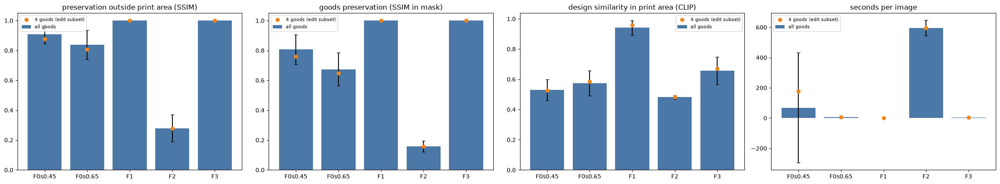

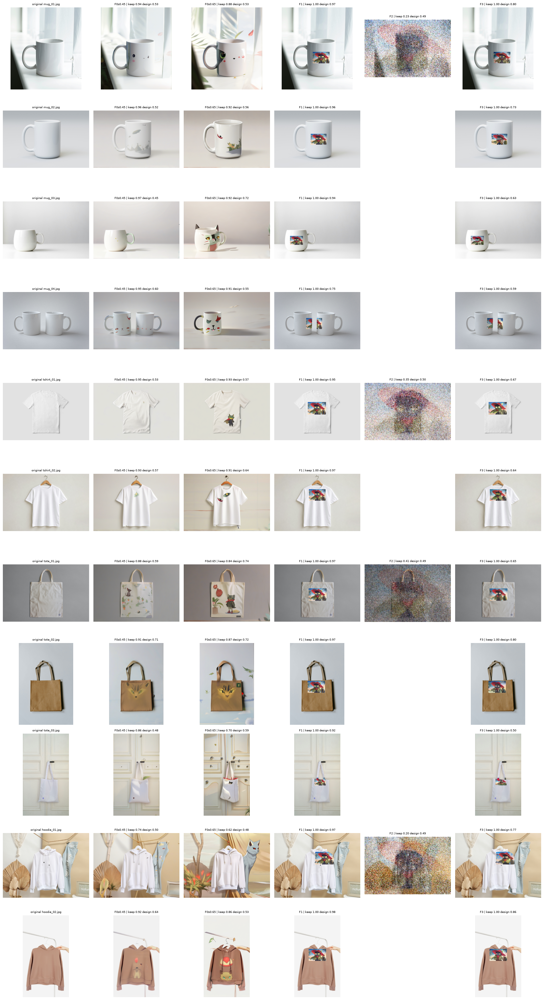

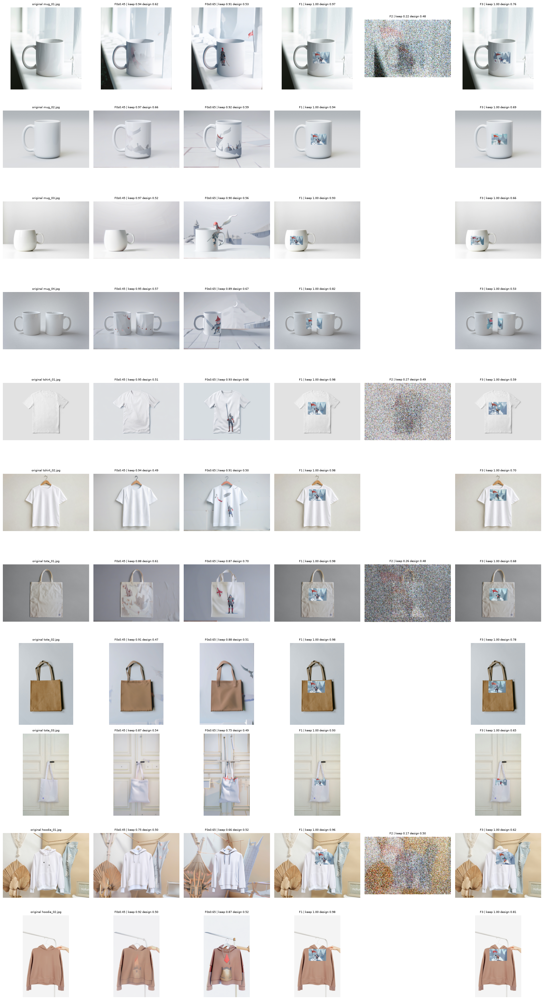

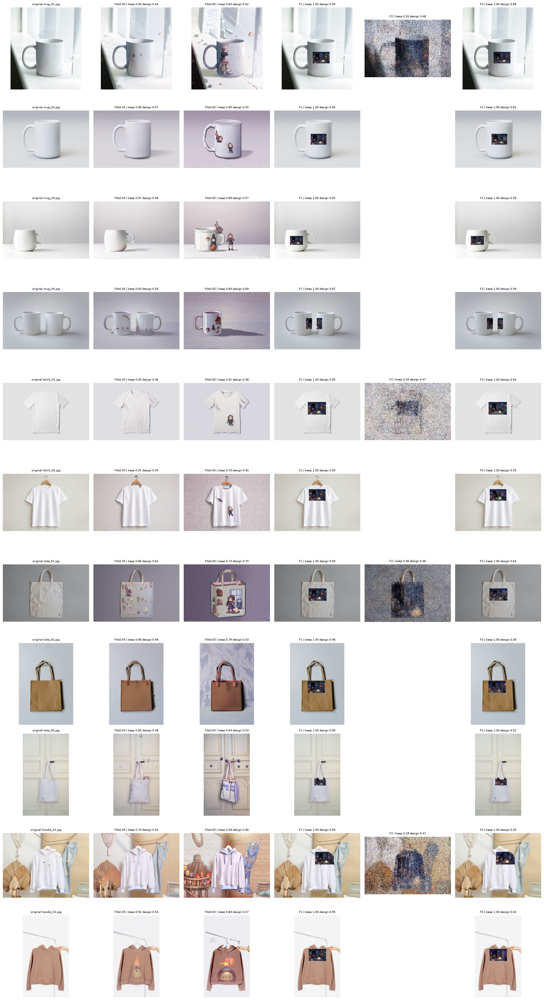

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(24, 4.5))
x = np.arange(len(METHODS))
for ax, col, title in zip(axes, ['keep_ssim', 'prod_ssim', 'design_sim', 'sec'],
                          ['preservation outside print area (SSIM)', 'goods preservation (SSIM in mask)',
                           'design similarity in print area (CLIP)', 'seconds per image']):
    ax.bar(x, summ_all[(col, 'mean')], yerr=summ_all[(col, 'std')].fillna(0), capsize=3, color='#4C78A8', label='all goods')
    ax.scatter(x, summ_sub[col], color='#F58518', zorder=3, label='4 goods (edit subset)')
    ax.set_xticks(x, METHODS)
    ax.set_title(title)
    ax.legend(fontsize=8)
for ax in axes[:2]:
    ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig(OUT_DIR / 'f_scores.png', dpi=90)
plt.show()

# 그림별 비교: 행 = 굿즈, 열 = 원본 + 방식
for game in DESIGNS:
    sub = GOODS.file.tolist()
    fig, axes = plt.subplots(len(sub), len(METHODS) + 1, figsize=(3.2 * (len(METHODS) + 1), 3.2 * len(sub)), squeeze=False)
    for i, name in enumerate(sub):
        axes[i, 0].imshow(load_goods(name))
        axes[i, 0].set_title(f'original {name}', fontsize=7)
        for j, m in enumerate(METHODS):
            r = fs[(fs.goods == name) & (fs.design == game) & (fs.method == m)]
            if len(r):
                r = r.iloc[0]
                axes[i, j + 1].imshow(Image.open(OUT_DIR / r.file))
                axes[i, j + 1].set_title(f'{m} | keep {r.keep_ssim:.2f} design {r.design_sim:.2f}', fontsize=7)
        for ax in axes[i]:
            ax.axis('off')
    plt.tight_layout()
    plt.savefig(OUT_DIR / f'f_grid_{game}.png', dpi=50)
    plt.show()